In [29]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from sklearn.datasets import fetch_california_housing
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

In [3]:
data = fetch_california_housing()

In [5]:
print(data.data.shape)
print(len(data.target))

(20640, 8)
20640


In [6]:
# 하이퍼파라미터
num_epochs = 500
batch_size = 32
lr = 0.01

In [10]:
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [11]:
X_train, X_test, y_train, y_test = train_test_split(df.loc[:, data.feature_names], df['target'], test_size=0.2)

In [12]:
print(X_train.shape)
print(X_test.shape)

(16512, 8)
(4128, 8)


In [19]:
# 커스텀 데이터셋: Dataset 상속 받아서 __init__, __len__, __getitem__  오버라이드
class CustomDataset(Dataset):
    def __init__(self, X, y, normalize=True):
        super(CustomDataset, self).__init__()

        if normalize:
            scaler = StandardScaler()
            X = scaler.fit_transform(X)

        self.x = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y.values, dtype=torch.float32)

    def __len__(self):
        return len(self.x)

    def __getitem__(self, idx):
        return self.x[idx], self.y[idx]

In [20]:
train_ds = CustomDataset(X_train, y_train)
test_ds = CustomDataset(X_test, y_test)

In [21]:
train = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
test = DataLoader(test_ds, batch_size=batch_size, shuffle=True)

In [22]:
x_batch, y_batch = next(iter(train))
print(x_batch.shape)
print(y_batch.shape)

torch.Size([32, 8])
torch.Size([32])


In [23]:
class Net(nn.Module):
    def __init__(self, num_features):
        super(Net, self).__init__()
        self.fc1 = nn.Linear(num_features, 32)
        self.fc2 = nn.Linear(32, 8)
        self.fc3 = nn.Linear(8, 1)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

In [24]:
# 모델, 데이터(x, y)을 device에 올림
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(device)

cpu


In [25]:
# 모델
model = Net(len(data.feature_names))
model.to(device)
model

Net(
  (fc1): Linear(in_features=8, out_features=32, bias=True)
  (fc2): Linear(in_features=32, out_features=8, bias=True)
  (fc3): Linear(in_features=8, out_features=1, bias=True)
)

In [27]:
# loss, optimizer
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=lr)

In [28]:
# 학습
losses = []
for epoch in range(num_epochs):
    running_loss = 0
    for x, y in train:
        x = x.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        y_hat = model(x)
        loss = criterion(y, y_hat)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    loss = running_loss / len(x)
    losses.append(loss)

    if epoch % 20 == 0:
        print(f'epoch: {epoch}, loss: {loss:.3f}')

print('-----'*10)
print(f'epoch: {epoch}, loss: {loss:.3f}')

/usr/local/lib/python3.12/dist-packages/torch/nn/modules/loss.py:626: UserWarning: Using a target size (torch.Size([32, 1])) that is different to the input size (torch.Size([32])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


epoch: 0, loss: 23.846
epoch: 20, loss: 21.572
epoch: 40, loss: 21.578
epoch: 60, loss: 21.581
epoch: 80, loss: 21.571
epoch: 100, loss: 21.582
epoch: 120, loss: 21.583
epoch: 140, loss: 21.575
epoch: 160, loss: 21.574
epoch: 180, loss: 21.571
epoch: 200, loss: 21.571
epoch: 220, loss: 21.572
epoch: 240, loss: 21.575
epoch: 260, loss: 21.578
epoch: 280, loss: 21.582
epoch: 300, loss: 21.566
epoch: 320, loss: 21.581
epoch: 340, loss: 21.574
epoch: 360, loss: 21.569
epoch: 380, loss: 21.576
epoch: 400, loss: 21.565
epoch: 420, loss: 21.572
epoch: 440, loss: 21.575
epoch: 460, loss: 21.559
epoch: 480, loss: 21.570
--------------------------------------------------
epoch: 499, loss: 21.572


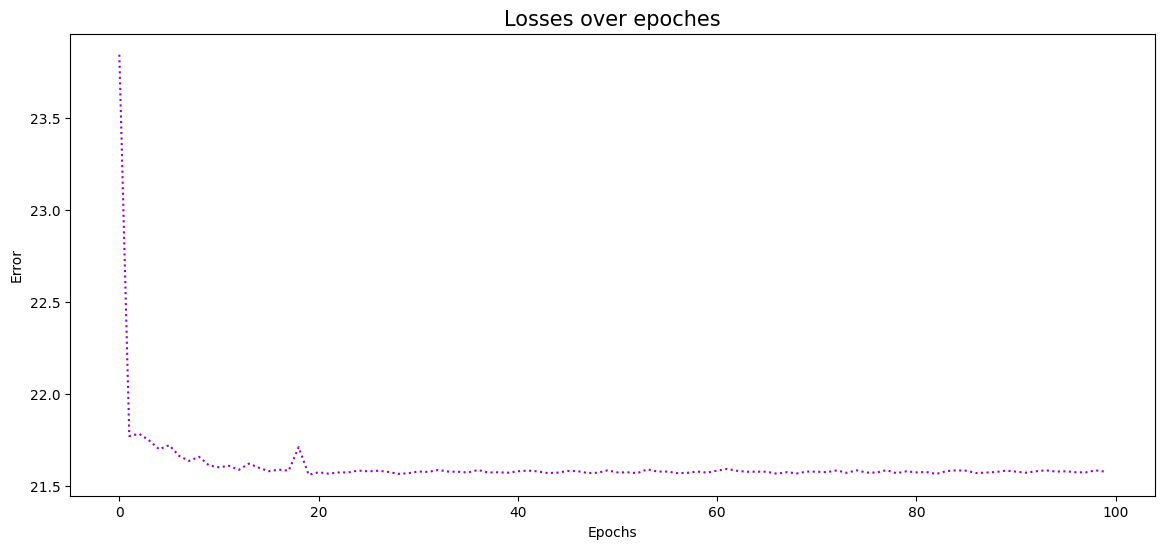

In [30]:
# 전체 loss 에 대한 변화량 시각화
plt.figure(figsize=(14, 6))
plt.plot(losses[:100], c='darkviolet', linestyle=':')

plt.title('Losses over epoches', fontsize=15)
plt.xlabel('Epochs')
plt.ylabel('Error')
plt.show()